In [1]:
from hydra import compose, initialize
from omegaconf import OmegaConf
import os

initialize(config_path="config")
cwd = os.getcwd()
pwd = cwd

/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_53842/682548894.py:5: UserWarning: 
The version_base parameter is not specified.
Please specify a compatability version level, or None.
Will assume defaults for version 1.1
  initialize(config_path="config")


In [2]:
config = compose(config_name="config", overrides=["datasets=ba_2motifs", "models=gcn_old"])

In [3]:
from dataset import get_dataset, get_dataloader
import torch

config.datasets.dataset_root = os.path.join(pwd, "dataset")
config.models.param = config.models.param[config.datasets.dataset_name]
dataset = get_dataset(
    dataset_root=config.datasets.dataset_root,
    dataset_name=config.datasets.dataset_name,
)
dataset.data.x = dataset.data.x.float()
dataset.data.y = dataset.data.y.squeeze().long()
if config.models.param.graph_classification:
    dataloader_params = {
        "batch_size": config.models.param.batch_size,
        "random_split_flag": config.datasets.random_split_flag,
        "data_split_ratio": config.datasets.data_split_ratio,
        "seed": config.datasets.seed,
    }
    loader = get_dataloader(dataset, **dataloader_params)
    test_indices = loader["test"].dataset.indices
    if config.datasets.data_explain_cutoff > 0:
        test_indices = test_indices[: config.datasets.data_explain_cutoff]

else:
    node_indices_mask = (dataset.data.y != 0) * dataset.data.test_mask
    node_indices = torch.where(node_indices_mask)[0]
    
from model.gnnNets import get_gnnNets
model = get_gnnNets(
    input_dim=dataset.num_node_features,
    output_dim=dataset.num_classes,
    model_config=config.models,
)

state_dict = torch.load(
    os.path.join(
        config.models.gnn_saving_path,
        f"{config.datasets.dataset_name}",
        f"{config.models.gnn_name}_"
        f"{len(config.models.param.gnn_latent_dim)}l_latest.pth",
    )
)["net"]

model.load_state_dict(state_dict)

/Users/admin/Documents/Screenshots/LORE/.env/lib/python3.12/site-packages/dig/xgraph/dataset/syn_dataset.py:58: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.data, self

<All keys matched successfully>

In [4]:
import random
from torch_geometric.utils.convert import to_networkx
from torch_geometric.utils import from_networkx
import copy
import torch
import networkx as nx
import torch.nn.functional as F
from distance import *
from utils import *

def prepare_networkx_for_pyg(graph_nx):
    for _, data in graph_nx.nodes(data=True):
        for k, v in data.items():
            if isinstance(v, list):
                data[k] = torch.tensor(v, dtype=torch.float)
    for _, _, data in graph_nx.edges(data=True):
        for k, v in data.items():
            if isinstance(v, list):
                data[k] = torch.tensor(v, dtype=torch.float)

def add_bidirectional_edges(edge_index):
    edge_set = set()
    unique_edges = []
    
    for i in range(edge_index.shape[1]):
        u, v = edge_index[:, i].tolist()
        edge = tuple(sorted((u, v)))
        
        if edge not in edge_set:
            edge_set.add(edge)
            unique_edges.append([u, v])

    bidirectional_edges = []
    for u, v in unique_edges:
        bidirectional_edges.append([u, v])
        bidirectional_edges.append([v, u])
    
    return torch.tensor(bidirectional_edges, dtype=torch.long).T

def eval_fitness_so(child_nx, graphX_nx, blackbox):    
    child = from_networkx(child_nx.graph)
    graphX = from_networkx(graphX_nx)
    
    logits_X, embedding_X = blackbox(graphX.x, graphX.edge_index, None)
    logits_G, embedding_G = blackbox(child.x, child.edge_index, None)
    # probX = F.softmax(torch.tensor(logits_X, dtype=torch.float), dim=1)
    # probG = F.softmax(torch.tensor(logits_G, dtype=torch.float), dim=1)
    # labelX = torch.argmax(probX).item()
    # labelG = torch.argmax(probG).item()
    distance = torch.norm(F.normalize(embedding_X, p=2, dim=1) - F.normalize(embedding_G, p=2, dim=1), p=2).item()

    if distance <= 0:
        distance = 1
    # distance = 0 if labelX == labelG else 1
    return distance

def eval_fitness_do(child_nx, blackbox, DO_graphs):
    
    child = from_networkx(child_nx.graph)
    logits_G, embedding_G = blackbox(child.x, child.edge_index, None)
    # probG = F.softmax(torch.tensor(logits_G, dtype=torch.float), dim=1)
    # label_G = torch.argmax(probG).item()
    uG = F.normalize(embedding_G, p=2, dim=1)
    distances = []
    for uX in DO_graphs:
        #probX = F.softmax(torch.tensor(uX, dtype=torch.float), dim=1)
        distance = torch.norm(uX - uG, p=2).item()
        if distance <= 0:
           continue
        
        # probX = torch.sigmoid(torch.tensor(uX, dtype=torch.float))
        # label_X = torch.argmax(probX).item()
        # distance = 0 if label_G == label_X else 1
    
        distances.append(distance)
        
    if not distances:
        return 1

    distance = min(distances)
    return distance


class Individual:
    def __init__(self, graph):
        self.graph = graph
        self.fitness = 0

    def clone(self):
        return Individual(copy.deepcopy(self.graph))

    def mutate(self, graphX, blackbox, case_type, DO_graphs):
        mutation_choices = ['add_edge', 'remove_edge']
        mutation_probs = [0.5, 0.5]
        mutation_type = random.choices(mutation_choices, weights=mutation_probs, k=1)[0]

        mutated_graph = copy.deepcopy(self.graph)
        if mutated_graph.nodes is None or mutated_graph.edges is None:
            return None
        
        any_node = next(iter(mutated_graph.nodes))
        feature_dim = len(mutated_graph.nodes[any_node].get('x'))
        nodes = list(mutated_graph.nodes)
        edges = list(mutated_graph.edges)

        if mutation_type == 'add_edge':
            for _ in range(10):
                u, v = random.sample(nodes, 2)
                if not mutated_graph.has_edge(u, v):
                    mutated_graph.add_edge(u, v)
                    break

        elif mutation_type == 'remove_edge' and edges:
            u, v = random.choice(edges)
            mutated_graph.remove_edge(u, v)

        elif mutation_type == 'add_node':
            new_node_id = max(mutated_graph.nodes) + 1
            new_feature = torch.zeros(feature_dim, dtype=torch.float)
            node_label = random.choice(range(feature_dim))
            new_feature[node_label] = 1
            
            mutated_graph.add_node(new_node_id, x=new_feature)
            
            existing_node = random.choice(nodes)
            if existing_node != new_node_id:
                mutated_graph.add_edge(new_node_id, existing_node)

        elif mutation_type == 'remove_node':
            node = random.choice(nodes)
            mutated_graph.remove_node(node)

        else: #change node label
            node_id = random.choice(nodes)
            old_feature = torch.tensor(mutated_graph.nodes[node_id]['x'], dtype=torch.float)
            current_index = torch.argmax(old_feature).item()
            
            other_indexes = [i for i in range(feature_dim) if i != current_index]
            new_index = random.choice(other_indexes)

            new_feature = torch.zeros(feature_dim, dtype=torch.float)
            new_feature[new_index] = 1.0
            mutated_graph.nodes[node_id]['x'] = new_feature

        if len(mutated_graph.nodes) < 2 or len(mutated_graph.edges) < 1:
            return None
        
        if not nx.is_connected(mutated_graph):
            return None
        
        prepare_networkx_for_pyg(mutated_graph)
        child = Individual(mutated_graph)
        if case_type == 'sso':
            child.fitness = eval_fitness_so(child, graphX, blackbox)
        else:
            child.fitness = eval_fitness_do(child, blackbox, DO_graphs)
        return child

    def crossover(self, other, graphX, blackbox, case_type, DO_graphs):
        G1 = copy.deepcopy(self.graph)
        G2 = copy.deepcopy(other.graph)

        nodes1 = list(G1.nodes)
        nodes2 = list(G2.nodes)

        if len(nodes1) < 3 or len(nodes2) < 3:
            return None 
        cut1, cut2 = sorted(random.sample(range(len(nodes1)), 2))

        part1 = nodes1[:cut1]                  
        part2 = nodes2[cut1:cut2]              
        part3 = nodes1[cut2:]                    
        selected_nodes = part1 + part2 + part3
        child = nx.Graph()

        for n in selected_nodes:
            if n in G1:
                child.add_node(n, **G1.nodes[n])
            elif n in G2:
                child.add_node(n, **G2.nodes[n])

        for G in [G1, G2]:
            for u, v in G.edges:
                if u in selected_nodes and v in selected_nodes:
                    child.add_edge(u, v)
        if not nx.is_connected(child):
            return None

        prepare_networkx_for_pyg(child)
        child = Individual(child)
        if case_type == 'sso':
            child.fitness = eval_fitness_so(child, graphX, blackbox)
        else:
            child.fitness = eval_fitness_do(child, blackbox, DO_graphs)

        return child

def initialize_population(size, graphX, blackbox, case_type, DO_graphs):
    population = []
    while len(population) < size:
        ind_graph = copy.deepcopy(graphX)
        ind = Individual(ind_graph).mutate(graphX, blackbox, case_type, DO_graphs)
        if ind is None:
            continue
        population.append(ind)
    return population

def select_parents(population, ratio):
    unique = {}
    for ind in population:
        if ind.fitness not in unique:
            unique[ind.fitness] = ind
    distinct = list(unique.values())
    distinct.sort(key=lambda x: x.fitness)
    return distinct[:int(ratio * len(distinct))]

def get_graphs_DO_embedding(label, dataset, blackbox):
    DO_graphs_embedding = []
    for i in range(len(dataset)):
        if dataset[i].y.item() != label:
            logits_X, embedding_X = blackbox(dataset[i].x, dataset[i].edge_index, None)
            uX = F.normalize(embedding_X, p=2, dim=1)
            DO_graphs_embedding.append(uX)
            
    print("Number of graphs with different labels: ", len(DO_graphs_embedding))
    return DO_graphs_embedding

def genetic_algorithm(graphX, population_size, generations, blackbox, test_dataset):
    DO_graphs_embedding = get_graphs_DO_embedding(graphX.graph['y'], test_dataset, blackbox)
    case_types = ['sdo']
    populations = {}

    for case_type in case_types:
        population = initialize_population(population_size // 2, graphX, blackbox, case_type, DO_graphs_embedding)
        
        for gen in range(generations):
            print(f"{case_type} : Generation {gen+1}/{generations}")
            new_population = []
            parents_pool = select_parents(population, ratio = 0.1) 
            new_population.extend(parents_pool[:len(parents_pool) // 2])
            fitness_set = set(ind.fitness for ind in new_population)

            while len(new_population) < (population_size // 2):
                p1, p2 = random.sample(parents_pool, 2)
                
                child = p1.crossover(p2, graphX, blackbox, case_type, DO_graphs_embedding)
                if child is None:
                    continue
                child = child.mutate(graphX, blackbox, case_type, DO_graphs_embedding)
                if child is None:
                    continue
                if all(abs(child.fitness - f) > 1e-8 for f in fitness_set):
                    fitness_set.add(child.fitness)
                    new_population.append(child)
                    
            population = new_population
            
        populations[case_type] = population
    return populations

In [25]:
test_indices = sorted(test_indices)
test_dataset = dataset[test_indices]

In [73]:
id = 807
graphX = copy.deepcopy(dataset[id])
print("Label of graphX: ", graphX.y.item())
graphX = to_networkx(graphX, to_undirected=True, node_attrs="x")
graphX.graph['y'] = dataset[id].y.item()
final_populations = genetic_algorithm(graphX=graphX, population_size=500, generations=2, 
                                blackbox= model, test_dataset=test_dataset)

Label of graphX:  1
Number of graphs with different labels:  12
sso : Generation 1/2
sso : Generation 2/2
sdo : Generation 1/2
sdo : Generation 2/2


In [68]:
sum_fitness = 0
for case_type, population in final_populations.items():
    for ind in population:
        sum_fitness += ind.fitness
print("Total fitness of all individuals: ", sum_fitness)
avg_fitness = sum_fitness / 500
avg_fitness
std_fitness = np.std([ind.fitness for ind in population])

mean_fitness = np.mean([ind.fitness for ind in population])
mean_fitness, std_fitness

Total fitness of all individuals:  268.53580615483224


(np.float64(0.5967655658647418), np.float64(0.3021288615389319))

In [ ]:
len(final_populations['sdo'])

200

In [ ]:
for pop in final_populations['sdo']:
    graph = from_networkx(pop.graph)
    logits, _ = model(graph.x, graph.edge_index, None)
    label = torch.sigmoid(torch.tensor(logits, dtype=torch.float)).argmax(dim=1).item()
    fitness = pop.fitness
    if label != fitness:
        print("Predicted label: ", label, "Fitness: ", pop.fitness)


/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_9741/1273827881.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  label = torch.sigmoid(torch.tensor(logits, dtype=torch.float)).argmax(dim=1).item()


Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0
Predicted label:  1 Fitness:  0


In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.utils import to_networkx, remove_isolated_nodes, to_undirected
from torch_geometric.data import Data
import networkx as nx
import matplotlib.pyplot as plt
import torch

def generate_population_dataframe(population, model, save_dir, pos = None):
    os.makedirs(save_dir, exist_ok=True)
    
    records = []
    
    for i, individual in enumerate(population):
        img_path = os.path.join(save_dir, f"graph_{i}.png")
        visualize_mutag_graph(
            individual.graph,
            save_path=img_path,
            pos=pos,
        )
        
        with torch.no_grad():
            data = from_networkx(individual.graph)
            logits, graph_emb = model(data.x, add_bidirectional_edges(data.edge_index), None)
            probs = F.softmax(logits, dim=-1)
            pred = probs.argmax().item()
            embedding = F.softmax(graph_emb, dim=-1).squeeze().cpu().numpy()
            embedding = embedding.tolist()
            embedding = [round(x, 6) for x in embedding]

        records.append({
            "img_path": img_path,
            "prediction": pred,
            "output": probs.squeeze().cpu().numpy().tolist(),
            "embedding": embedding,
            "fitness": getattr(individual, 'fitness', None) 
        })

    return pd.DataFrame(records)


In [74]:
pos = nx.spring_layout(graphX, seed = 55)
final_populations['sso'] = sorted(final_populations['sso'], key=lambda x: x.fitness, reverse=True)
final_populations['sdo'] = sorted(final_populations['sdo'], key=lambda x: x.fitness, reverse=True)
df_sso = generate_population_dataframe(final_populations['sso'], model, 
                                       save_dir=f"visualization/{config.datasets.dataset_name}/population_sso",
                                       pos = pos)
df_sdo = generate_population_dataframe(final_populations['sdo'], model, 
                                       save_dir=f"visualization/{config.datasets.dataset_name}/population_sdo",
                                        pos =pos)
df_sdo.to_csv(f"visualization/{config.datasets.dataset_name}/population_sdo.csv", index=False)
df_sso.to_csv(f"visualization/{config.datasets.dataset_name}/population_sso.csv", index=False)

img_path = os.path.join("visualization", f"graph_X.png")

visualize_mutag_graph(
    graphX,
    save_path=img_path,
    pos = pos
)

In [70]:
def visualize(df, file_name):
    f = open(file_name, "wt", encoding='utf-8')
    f.write("<html>\n")
    f.write("<body>\n")
    f.write("<h2>Final population</h2>\n")
    f.write("<table border='1' cellspacing='0' cellpadding='10'>\n")
    f.write("<h2 style='text-align: center;'><img src='visualization/graph_X.png' width='300'></h2>")
    for i in range(df.shape[0]):
        row = df.iloc[i]
        img_path = row['img_path']
        pred = row['prediction']
        embedding = row['embedding']

        f.write("<tr>")
        f.write(f"<td><img src='{img_path}' width='300' height='300'></td>")
        f.write(f"<td><b>Prediction:</b> {pred}<br><b>Embedding:</b> [{embedding}]<br><b>Output:</b> {row['output']}</td>")
        f.write(f"<td><b>Distance:</b> {row['fitness']}</td>")
        f.write("</tr>\n")
    f.write("</table>\n")
    f.write("</body>\n")
    f.write("</html>\n")
    f.close()

visualize(df_sso, f"{config.datasets.dataset_name}_population_sso.html")
visualize(df_sdo, f"{config.datasets.dataset_name}_population_sdo.html")

In [26]:
import pandas as pd
import torch
import numpy as np
from model.gin import *
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
population = final_populations['sso'] + final_populations['sdo']
list_graph = []
for individual in population:
    graph = from_networkx(individual.graph)
    list_graph.append(graph)
df = prepare_dataframe(list_graph, model, device, ground_truth=False, only_edge=True, node_label=False)

class_1 = df[df['y'] == 1].shape[0]
class_0 = df[df['y'] == 0].shape[0]
class_1, class_0

(379, 21)

In [43]:
import networkx as nx
import numpy as np

def graph_to_binary_vector(G, node_order):
    n = len(node_order)
    idx_map = {node: i for i, node in enumerate(node_order)}
    vec = []

    for i in range(n):
        for j in range(i + 1, n):
            u, v = node_order[i], node_order[j]
            if G.has_edge(u, v):
                vec.append(1)
            else:
                vec.append(0)
    return np.array(vec, dtype=int)

def match_distance_binary(G1, G2):
    all_nodes = sorted(set(G1.nodes()) | set(G2.nodes()))
    
    v1 = graph_to_binary_vector(G1, all_nodes)
    v2 = graph_to_binary_vector(G2, all_nodes)
    intersection = np.sum((v1 == 1) & (v2 == 1))
    union = np.sum((v1 == 1) | (v2 == 1))

    if union == 0:
        return 0.0  
    return 1 - intersection / union

G1 = to_networkx(dataset[0], to_undirected=True, node_attrs="x")
G2 = to_networkx(dataset[999], to_undirected=True, node_attrs="x")
dist = match_distance_binary(G1, G2)
dist

np.float64(0.813953488372093)

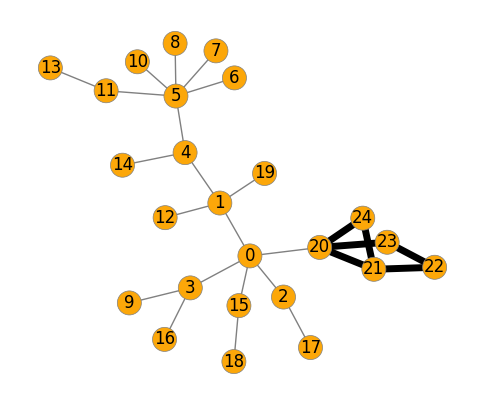

In [8]:
rule = {'n20_n24': '>0', 'n20_n21': '>0', 'n22_n23': '>0', 'n21_n22': '>0', 'n20_n23': '>0', 'n21_n24': '>0'}
important_nodes = [k for k in rule if k.startswith('nL_')]
important_edges = [k for k in rule if k.startswith('n') and '_n' in k]
G = to_networkx(dataset[838], to_undirected=True, node_attrs="x")
visualize_mutag_graph(G, important_nodes=important_nodes, important_edges=important_edges, pos = nx.kamada_kawai_layout(G))